In [1]:
import torch
from torch import nn

# 固定随机数种子
torch.manual_seed(42)

x = torch.linspace(-1, 1, 100).unsqueeze(1)
y = 2 * x + 1

model = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

with torch.no_grad():
    initial_loss = loss_fn(model(x), y).item()

print("Initial loss:", initial_loss)
print("Initial weight:", model.weight.item())
print("Initial bias:", model.bias.item())

Initial loss: 0.5479642152786255
Initial weight: 0.7645385265350342
Initial bias: 0.8300079107284546


In [2]:
def train(model, x, y, loss_fn, optimizer, epochs=100):
    history = []

    for epoch in range(epochs):
        # 1. 清除上一轮累积的梯度
        # PyTorch 的梯度默认是累加的(每个参数的 .grad 会不断加上新算出的梯度)。如果不先清零,当前轮的梯度会叠旧梯度上,导致参数更新方向错误。
        optimizer.zero_grad()

        # 2. Forward Pass
        # 数据 x 从输入层流过网络的每一层,最终输出值 y_pred
        y_pred = model(x)

        # 3. Calculate Loss
        # 计算损失。把预测值和真实值 y 一起喂给损失函数,得到一个标量,数值越小说明预测越准。这个 loss 是整个训练的目标——我们要让它的值尽量小。
        loss = loss_fn(y_pred, y)

        # 4. Backward Pass
        # 反向传播(Backward Pass)。这是自动微分(autograd)的关键一步:PyTorch会从 loss 出发,沿着计算图往回计算每个参数对 loss 的偏导数(即梯度),存到各参数的 .grad 属性里。梯度告诉你"往哪个方向调参数,loss 会下降"。
        loss.backward()

        # 5. Update Parameters
        # 参数更新。优化器读取每个参数的 .grad,沿着梯度的反方向走一小步(步长由学习率 lr 控制)
        optimizer.step()

        # 把每一轮的损失记录下来,.item() 是把单元素张量转成 Python 浮点数(脱离计算图)。
        history.append(loss.item())

        if (epoch + 1) % 20 == 0:
            print(
                f"Epoch [{epoch + 1}/{epochs}], "
                f"Loss: {loss.item():.6f}"
            )

    return history

history = train(
    model,
    x,
    y,
    loss_fn,
    optimizer,
    epochs=100
)

Epoch [20/100], Loss: 0.139920
Epoch [40/100], Loss: 0.034938
Epoch [60/100], Loss: 0.008753
Epoch [80/100], Loss: 0.002193
Epoch [100/100], Loss: 0.000550


In [3]:
with torch.no_grad():
    final_loss = loss_fn(model(x), y).item()

print("Initial loss:", initial_loss)
print("Final loss:", final_loss)
print("Trained weight:", model.weight.item())
print("Trained bias:", model.bias.item())

assert final_loss < initial_loss
assert abs(model.weight.item() - 2.0) < 0.1
assert abs(model.bias.item() - 1.0) < 0.1

Initial loss: 0.5479642152786255
Final loss: 0.0005129075143486261
Trained weight: 1.9611637592315674
Trained bias: 0.9999954700469971


In [4]:
p = torch.nn.Parameter(torch.tensor(1.0))

(p ** 2).backward()
print(p.grad)  # tensor(2.)

(p ** 2).backward()
print(p.grad)  # tensor(4.)

p.grad = None
(p ** 2).backward()
print(p.grad)  # tensor(2.)

tensor(2.)
tensor(4.)
tensor(2.)


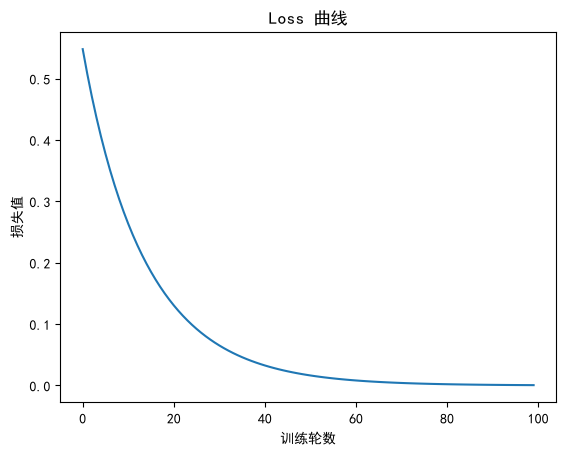

In [5]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]  # 黑体,Windows 自带
plt.rcParams["axes.unicode_minus"] = False    # 显示负号

plt.plot(history)
plt.xlabel("训练轮数")
plt.ylabel("损失值")
plt.title("Loss 曲线")
plt.show()

## ADM 收敛速度实验

固定数据和初始参数(每次用相同种子重建模型),只改变学习率 lr,观察 ADM 的收敛速度差异:
- lr 太小:收敛慢,100 轮还没训好
- lr 合适:快速稳定地下降
- lr 太大:震荡甚至发散

In [6]:
lrs = [0.01, 0.05, 0.5]
histories = {}

for lr in lrs:
    # 每次用相同种子重建模型,保证初始参数一致,对比才公平
    torch.manual_seed(42)
    model = nn.Linear(1, 1)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    print(f"===== lr = {lr} =====")
    histories[lr] = train(model, x, y, loss_fn, optimizer, epochs=100)
    print(f"lr={lr}: final loss = {histories[lr][-1]:.6f}\n")

===== lr = 0.01 =====
Epoch [20/100], Loss: 0.373005
Epoch [40/100], Loss: 0.251725
Epoch [60/100], Loss: 0.162083
Epoch [80/100], Loss: 0.099761
Epoch [100/100], Loss: 0.058514
lr=0.01: final loss = 0.058514

===== lr = 0.05 =====
Epoch [20/100], Loss: 0.044439
Epoch [40/100], Loss: 0.003632
Epoch [60/100], Loss: 0.000575
Epoch [80/100], Loss: 0.000137
Epoch [100/100], Loss: 0.000001
lr=0.05: final loss = 0.000001

===== lr = 0.5 =====
Epoch [20/100], Loss: 0.007030
Epoch [40/100], Loss: 0.003274
Epoch [60/100], Loss: 0.000094
Epoch [80/100], Loss: 0.000078
Epoch [100/100], Loss: 0.000007
lr=0.5: final loss = 0.000007



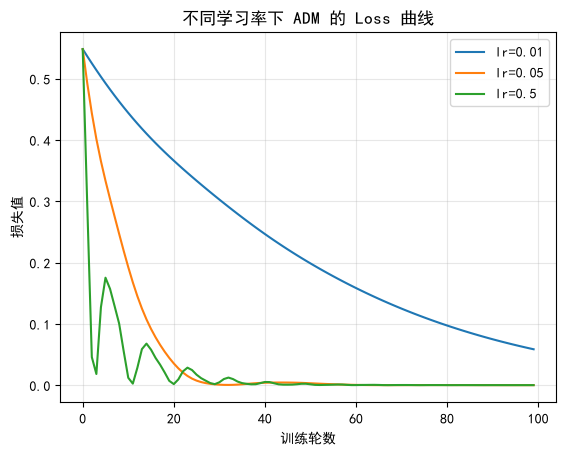

In [7]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]  # 黑体,Windows 自带
plt.rcParams["axes.unicode_minus"] = False    # 显示负号

for lr, h in histories.items():
    plt.plot(h, label=f"lr={lr}")

plt.xlabel("训练轮数")
plt.ylabel("损失值")
plt.title("不同学习率下 ADM 的 Loss 曲线")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()